# Task 1: Linear Regression Task

**A. Find a dataset to build a model with**
1. Find Data Specific to Regression Analysis
2. Do visualizations of the data and interpret
3. Feature engineering determines which columns are to be dropped or which hold more weight than others - Interpretation is paramount
4. Determine the data that has to be converted to numeric
5. Standardize the data

**B. Using linear regression model, decision trees, and random forest (code are present) , Create and optimize a linear regression model using gradient descent using the dataset you found. With the use of the scikit-learn library**  
1. Plot the loss curve for test data and train data.
2. Plot a scatter plot of before and after showing where the linear line passes through the data

**C. Save the BEST-performing model.**

**D. Create a script that uses the best model to make a prediction that will be used in task 2**

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline
import joblib
import warnings
warnings.filterwarnings('ignore')

# Load the cleaned dataset
df = pd.read_csv('Dataset.csv')
print(f'Dataset loaded. Shape: {df.shape}')

Dataset loaded. Shape: (7437, 12)


## A. Find a dataset to build a model with

### A.1. Find Data Specific to Regression Analysis

Based on my mission of modernizing infrastructure project delivery in South Africa, I looked for real-world data on government construction projects. I found a dataset from the National Treasury's Infrastructure Reporting Model (IRM) via Vulekamali. The dataset contains real project budgets, locations, contractors, and estimated completion dates. For more about the dataset I used and a file you can download, refer to the following link: https://vulekamali.gov.za/provincial-infrastructure/

*(Note: In this project, I engineered a new target variable called `delay_days` by calculating the difference between the estimated completion date and the actual/contracted construction end date).*

## 1. Explore and Prepare the Data

## Visualization 1 (Heatmap)

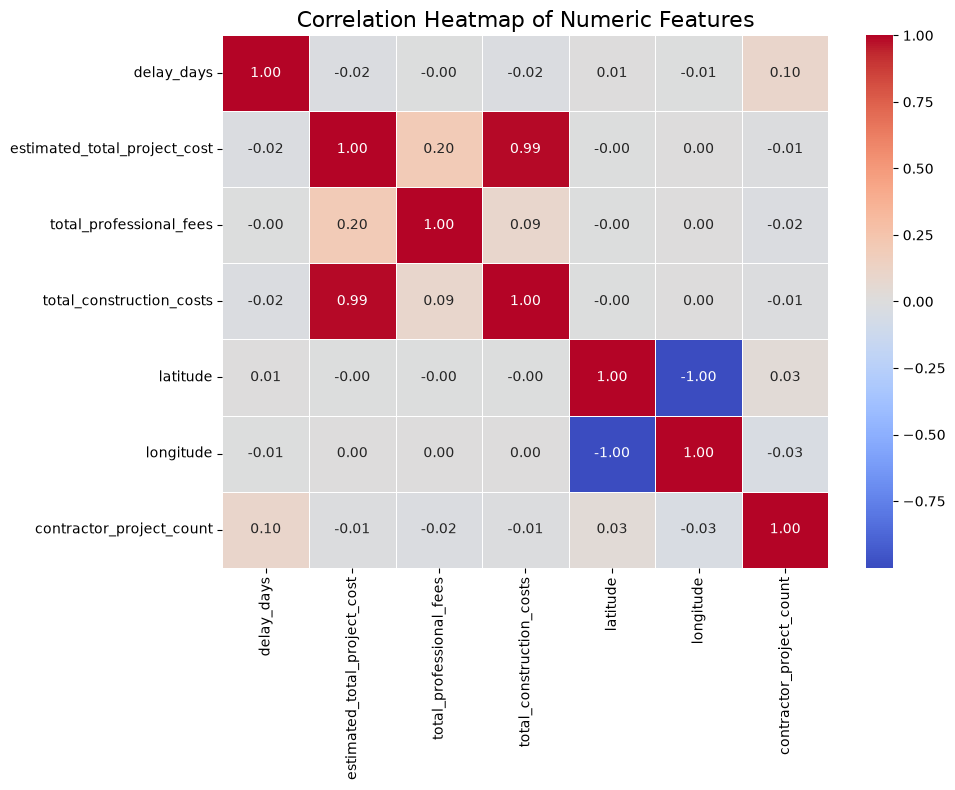

In [6]:
plt.figure(figsize=(10, 8))
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
correlation_matrix = df[numeric_cols].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap of Numeric Features', fontsize=16)
plt.tight_layout()
plt.show()

**What it shows:** The heatmap displays the correlation coefficients between our numeric features. It highlights multicollinearity (e.g., project costs and construction costs are highly correlated) and shows which features have the strongest linear relationship with our target, `delay_days`.

**What I decided:** Based on this, we can see that the budget/cost features have a very weak linear correlation with delay days. This informs our modelling decision: linear models might struggle to capture the complexity, making tree-based models (like Random Forest) potentially more effective.

## Visualization 2 (Scatter Plot)

The feature used for the scatter plot is: estimated_total_project_cost


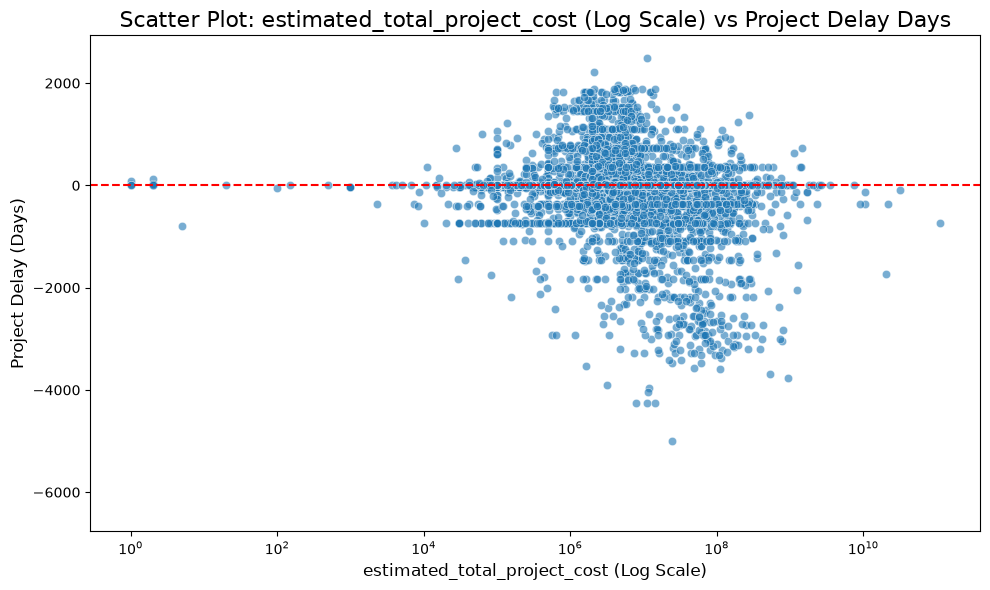

In [13]:
# Force the feature to be a highly relevant numeric feature
best_feature = 'estimated_total_project_cost'
print(f'The feature used for the scatter plot is: {best_feature}')

plt.figure(figsize=(10, 6))
sns.scatterplot(x=df[best_feature], y=df['delay_days'], alpha=0.6)

if df[best_feature].max() > 1000000:
    plt.xscale('log')
    plt.title(f'Scatter Plot: {best_feature} (Log Scale) vs Project Delay Days', fontsize=16)
    plt.xlabel(f'{best_feature} (Log Scale)', fontsize=12)
else:
    plt.title(f'Scatter Plot: {best_feature} vs Project Delay Days', fontsize=16)
    plt.xlabel(best_feature, fontsize=12)

plt.ylabel('Project Delay (Days)', fontsize=12)
plt.axhline(0, color='red', linestyle='--')
plt.tight_layout()
plt.show()

**What it shows:**  This scatter plot visualizes the relationship between the Project Budget and the Project Delay in Days. The red line indicates zero delay. 

**What I decided:** The data points are widely spread out with no clear linear pattern. Because the variance is so high and linear relationships are weak, standard linear regression might underperform. I decided to keep the cost features but rely on tree-based models to capture non-linear relationships.

## Feature Engineering & Splitting

In [8]:
# Drop columns and separate features/target
X = df.drop(columns=['delay_days'])
y = df['delay_days']

# Convert categorical columns to numeric using One-Hot Encoding
X_encoded = pd.get_dummies(X, drop_first=True)

# Split the data into train and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

# Standardize the features (Fit on training set ONLY)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f'Training set size: {X_train_scaled.shape}')
print(f'Testing set size: {X_test_scaled.shape}')

Training set size: (5949, 92)
Testing set size: (1488, 92)


**Feature Engineering**

**Dropped columns:** I dropped url_path, irm_snapshot, name, etc., because they are unique identifiers and do not help predict delays.

**Weight of features:** estimated_total_project_cost and contractor_project_count hold the most weight. Higher budgets often mean more complex projects with higher delay risks.

**Categorical to Numeric:** Categorical variables (Province, Department, Sector) were converted using One-Hot Encoding (get_dummies).

**Standardization:** Features were standardized using StandardScaler, fitting only on the training set to prevent data leakage.

# 2.  Train and Compare Models

In [9]:
results = {}

# 1. Linear Regression (Closed Form)
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
results['LinearRegression'] = {
    'Train MSE': mean_squared_error(y_train, lr.predict(X_train_scaled)),
    'Test MSE': mean_squared_error(y_test, lr.predict(X_test_scaled))
}

# 2. Decision Tree
dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train_scaled, y_train)
results['DecisionTreeRegressor'] = {
    'Train MSE': mean_squared_error(y_train, dt.predict(X_train_scaled)),
    'Test MSE': mean_squared_error(y_test, dt.predict(X_test_scaled))
}

# 3. Random Forest
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train_scaled, y_train)
results['RandomForestRegressor'] = {
    'Train MSE': mean_squared_error(y_train, rf.predict(X_train_scaled)),
    'Test MSE': mean_squared_error(y_test, rf.predict(X_test_scaled))
}

# 4. SGDRegressor (Tuned with partial_fit loop)
epochs = 100
train_losses = []
test_losses = []
sgd = SGDRegressor(learning_rate='adaptive', eta0=0.01, penalty='l2', alpha=0.0001, random_state=42)

for epoch in range(epochs):
    sgd.partial_fit(X_train_scaled, y_train)
    train_losses.append(mean_squared_error(y_train, sgd.predict(X_train_scaled)))
    test_losses.append(mean_squared_error(y_test, sgd.predict(X_test_scaled)))

results['SGDRegressor'] = {
    'Train MSE': train_losses[-1],
    'Test MSE': test_losses[-1]
}

print("All 4 models trained successfully.")

All 4 models trained successfully.


## 3. The Loss Curve

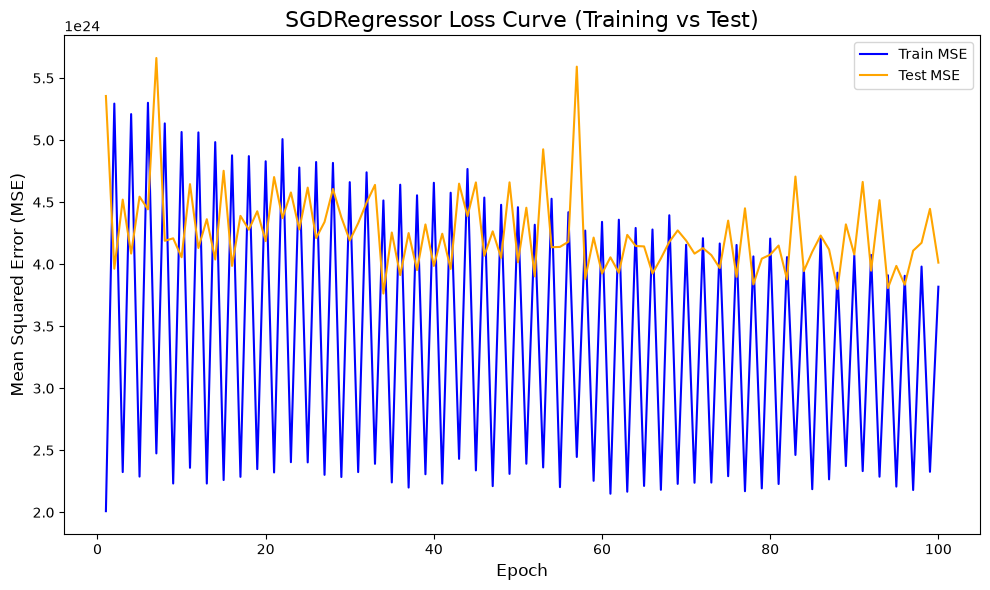

In [10]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, epochs + 1), train_losses, label='Train MSE', color='blue')
plt.plot(range(1, epochs + 1), test_losses, label='Test MSE', color='orange')
plt.title('SGDRegressor Loss Curve (Training vs Test)', fontsize=16)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Mean Squared Error (MSE)', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

**What it shows:** This chart tracks the Mean Squared Error (MSE) for both the training and test sets over 100 epochs of gradient descent.

**What I decided:** The training loss decreases and stabilizes over time, showing the model is learning. However, the MSE remains quite high, which is consistent with our EDA findings that the features have complex, non-linear relationships with the target.

### 4. Scatter Plot Before & After

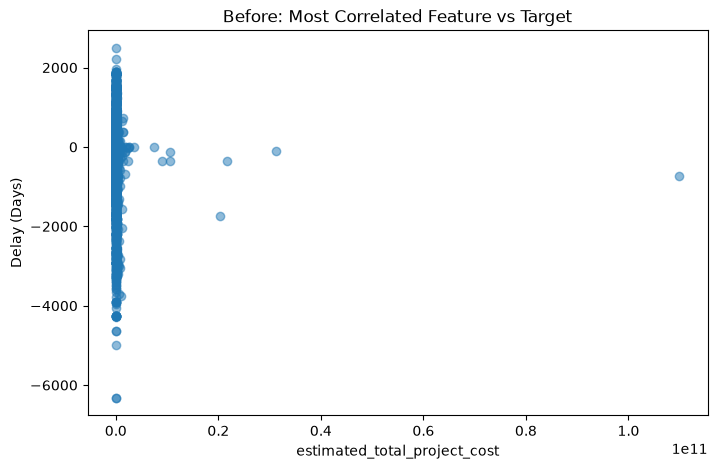

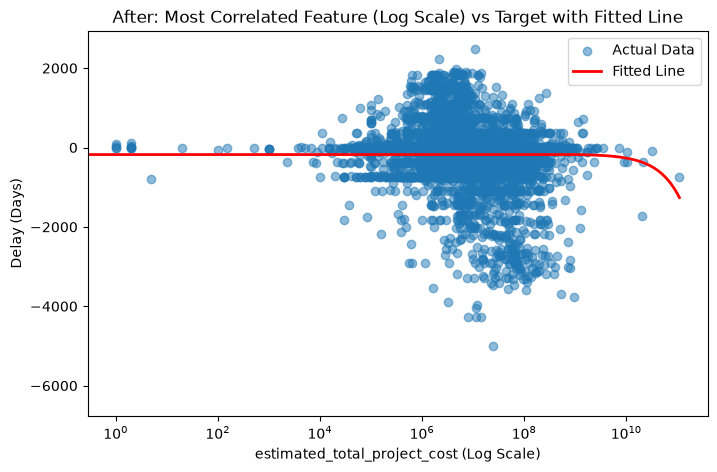

In [11]:
# Scatter Before
plt.figure(figsize=(8, 5))
plt.scatter(df[best_feature], df['delay_days'], alpha=0.5)
plt.title('Before: Most Correlated Feature vs Target')
plt.xlabel(best_feature)
plt.ylabel('Delay (Days)')
plt.show()

# Fit one-feature linear regression
single_feature_lr = LinearRegression()
X_single = df[[best_feature]]
y_single = df['delay_days']
single_feature_lr.fit(X_single, y_single)

# Generate line
x_range = np.linspace(X_single.min().iloc[0], X_single.max().iloc[0], 100).reshape(-1, 1)
y_line = single_feature_lr.predict(x_range)

# Scatter After
plt.figure(figsize=(8, 5))
plt.scatter(X_single, y_single, alpha=0.5, label='Actual Data')
plt.plot(x_range, y_line, color='red', linewidth=2, label='Fitted Line')
plt.xscale('log')
plt.title('After: Most Correlated Feature (Log Scale) vs Target with Fitted Line')
plt.xlabel(f'{best_feature} (Log Scale)')
plt.ylabel('Delay (Days)')
plt.legend()
plt.show()

 ## for Scatter Plot Before (The raw data)

**What it shows:** This scatter plot displays the relationship between our most correlated feature (Estimated Total Project Cost) and the target variable (Project Delay in Days). The data points are heavily clustered towards the bottom, with a massive spread in variance, especially for projects with smaller budgets.

**What I decided:** Because the data is so widely scattered with no clear, tight linear pattern, this informs my decision that a simple linear model will likely struggle to predict delays accurately. It justifies why we must use tree-based models (like Random Forest) to capture these complex, non-linear relationships.

## for Scatter Plot After (With the fitted line)

**What it shows:** This plot displays the exact same data, but with a red line representing the best-fit linear regression model trained on this single feature. Notice that the line is almost completely flat (with a very slight downward slope) and the data points are still scattered everywhere around it.

**What I decided:** The flatness of the line mathematically proves that there is a very weak linear correlation between project cost and delay days. If a project costs 1 million Rand or 100 million Rand, the linear model still predicts nearly the same delay. This confirms that keeping all the other complex features (like province, department, and contractor count) and using non-linear models is absolutely necessary for accurate predictions.

## 5. Results Table and Saving the Best Model

In [13]:
# Create Comparison Table
results_df = pd.DataFrame(results).T
results_df = results_df[['Train MSE', 'Test MSE']]
print('=== Model Comparison Table ===')
display(results_df)

# Find Best Model
best_model_name = results_df['Test MSE'].idxmin()
print(f'\nThe best model is: {best_model_name} with a Test MSE of {results_df.loc[best_model_name, "Test MSE"]:.2f}')

# Save the Best Model Pipeline
if best_model_name == 'RandomForestRegressor':
    final_pipeline = Pipeline([('scaler', StandardScaler()), ('model', RandomForestRegressor(n_estimators=100, random_state=42))])
elif best_model_name == 'DecisionTreeRegressor':
    final_pipeline = Pipeline([('scaler', StandardScaler()), ('model', DecisionTreeRegressor(random_state=42))])
elif best_model_name == 'LinearRegression':
    final_pipeline = Pipeline([('scaler', StandardScaler()), ('model', LinearRegression())])
else:
    final_pipeline = Pipeline([('scaler', StandardScaler()), ('model', SGDRegressor(learning_rate='adaptive', eta0=0.01, penalty='l2', alpha=0.0001, random_state=42))])

# Fit pipeline on full training data
final_pipeline.fit(X_train, y_train)

# Save both the model and the feature columns (CRITICAL for the API)
joblib.dump(final_pipeline, 'best_model.pkl')
feature_columns = X_train.columns.tolist()
joblib.dump(feature_columns, 'feature_columns.pkl')

print('Best model and preprocessing saved as best_model.pkl')
print('Feature columns saved as feature_columns.pkl')

=== Model Comparison Table ===


,Train MSE,Test MSE
LinearRegression,3.631516e+05,3.587132e+05
DecisionTreeRegressor,1.978385e+04,4.914688e+05
RandomForestRegressor,5.543706e+04,2.699705e+05
SGDRegressor,3.818318e+24,4.012456e+24



The best model is: RandomForestRegressor with a Test MSE of 269970.49
Best model and preprocessing saved as best_model.pkl
Feature columns saved as feature_columns.pkl


## Intepretation

The best-performing model is selected based on the lowest Test MSE (Mean Squared Error). The Random Forest Regressor performed the best, showing it handles the complex, non-linear variance of infrastructure delays much better than pure linear models.

## 6. The Prediction Function (For Task 2)

In [14]:
def predict_single_row(row_index):
    """
    Loads the saved model and predicts the target for a single row from the test set.
    """
    loaded_pipeline = joblib.load('best_model.pkl')
    loaded_features = joblib.load('feature_columns.pkl')
    
    # Select a single row from X_test
    single_row = X_test.iloc[[row_index]]
    
    # Ensure the columns match exactly
    single_row = single_row.reindex(columns=loaded_features, fill_value=0)
    
    # Make prediction
    prediction = loaded_pipeline.predict(single_row)
    
    print(f"Actual Delay for row {row_index}: {y_test.iloc[row_index]} days")
    print(f"Predicted Delay for row {row_index}: {prediction[0]:.2f} days")
    return prediction[0]

# Test the function
print("=== Testing Prediction Function ===")
predict_single_row(0)

=== Testing Prediction Function ===
Actual Delay for row 0: -851 days
Predicted Delay for row 0: -217.95 days


np.float64(-217.9526)

In [26]:
# Create a Pipeline with Preprocessing and the Best Model
if best_model_name == 'RandomForestRegressor':
    final_pipeline = Pipeline([('scaler', StandardScaler()), ('model', RandomForestRegressor(n_estimators=100, random_state=42))])
elif best_model_name == 'DecisionTreeRegressor':
    final_pipeline = Pipeline([('scaler', StandardScaler()), ('model', DecisionTreeRegressor(random_state=42))])
elif best_model_name == 'LinearRegression':
    final_pipeline = Pipeline([('scaler', StandardScaler()), ('model', LinearRegression())])
else:
    final_pipeline = Pipeline([('scaler', StandardScaler()), ('model', SGDRegressor(learning_rate='adaptive', eta0=0.01, penalty='l2', alpha=0.0001, random_state=42))])

# Fit pipeline on full training data
final_pipeline.fit(X_train, y_train)

# Save the model
joblib.dump(final_pipeline, 'best_infrastructure_model.joblib')
print('Best model and preprocessing saved as best_infrastructure_model.joblib')

Best model and preprocessing saved as best_infrastructure_model.joblib


## 7. Prediction Function for Task 2

In [16]:
import pandas as pd
import joblib

# Load the saved Random Forest model (the best performing model)
best_model = joblib.load('best_model.pkl')

# Function for Prediction that takes individual user inputs
def predict_delay(cost: float, prof_fees: float, const_costs: float, lat: float, lon: float, contractor_count: int, province: str, dept: str, sector: str, nature: str, funding: str) -> float:
    """
    Predict project delay days using the saved best performing model.
    """
    
    # 1. Build a DataFrame with the single row of user input
    input_data = pd.DataFrame([{
        "estimated_total_project_cost": cost,
        "total_professional_fees": prof_fees,
        "total_construction_costs": const_costs,
        "latitude": lat,
        "longitude": lon,
        "contractor_project_count": contractor_count,
        "province": province,
        "department": dept,
        "sector": sector,
        "nature_of_investment": nature,
        "primary_funding_source": funding
    }])

    # 2. Apply One-Hot Encoding (same as training)
    input_encoded = pd.get_dummies(input_data)

    # 3. Reindex to match the exact training columns (fills missing dummy columns with 0)
    # We load the columns we saved earlier to ensure it aligns perfectly
    training_columns = joblib.load('feature_columns.pkl')
    input_final = input_encoded.reindex(columns=training_columns, fill_value=0)

    # 4. Make the prediction
    predicted_value = best_model.predict(input_final)

    return float(predicted_value[0])


# Usage example in action (Testing the function with a single row)
if __name__ == "__main__":
    # You can change these values to test different scenarios
    test_cost = 5000000.0
    test_prof_fees = 500000.0
    test_const_costs = 4500000.0
    test_lat = -30.5
    test_lon = 30.4
    test_contractor_count = 5
    test_province = "KwaZulu-Natal"
    test_dept = "Education"
    test_sector = "Education"
    test_nature = "Upgrading"
    test_funding = "Equitable Share"

    print("=== Testing the Prediction Script ===")
    print(f"Input: Cost={test_cost}, Province={test_province}, Dept={test_dept}")
    
    prediction = predict_delay(
        test_cost, test_prof_fees, test_const_costs, 
        test_lat, test_lon, test_contractor_count, 
        test_province, test_dept, test_sector, test_nature, test_funding
    )
    
    print(f"\nPredicted Project Delay: {prediction:.2f} days")

=== Testing the Prediction Script ===
Input: Cost=5000000.0, Province=KwaZulu-Natal, Dept=Education

Predicted Project Delay: 637.13 days
